<a href="https://colab.research.google.com/github/Bsamuel-tech/FUTURE_DS_02/blob/main/MiniProject3_CLIP_Alignment_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-Project 3: Does Fine-Tuning Break CLIP's Text-Image Alignment?

**Labs reused:** Lab 10 (CLIP, contrastive learning, zero-shot) and Lab 11 (Fine-Tuning CLIP, Part B).

**Question.** In Lab 11 Part B we unfroze the last 2 vision blocks of CLIP plus `visual_projection` and trained them with a cross-entropy classification head on FashionMNIST. The text encoder was never touched and no loss asked the image and text sides to stay aligned. The fine-tuned model classifies better. Does it still retrieve well from text?

**Plan of the notebook**

| Section | Brief requirement |
|---|---|
| 0 | Setup and configuration |
| 1 | Prediction, written before any evaluation code (req. 2) |
| 2 | Fixed evaluation set (req. 1) |
| 3 | Reproduce the Lab 11 Part B fine-tuned CLIP |
| 4 | Retrieval system: text-to-image P@1/5/10, image-to-text top-1/3/5 (req. 3) |
| 5 | Zero-shot vs fine-tuned comparison table (req. 4) |
| 6 | Embedding drift: cosine(zero-shot, fine-tuned) per image (req. 5) |
| 7 | Real product photos (`ceyda/fashion-products-small`), 12 attribute queries, top-5, metadata relevance (req. 6) |
| 8 | Optional extension: image-to-image with CLIP, ViT-B/32, autoencoder (P@K, mAP, t-SNE) |
| 9 | Bonus: alignment-preserving fine-tuning (WiSE-FT interpolation, text-anchored fine-tuning) |
| 10 | Results summary (all numbers printed from the run) |
| 11 | Interactive Gradio demo: side-by-side zero-shot vs fine-tuned search, image classification, results dashboard |
| 12 | Discussion |

**How to run:** Google Colab, `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`. Training Part B (Section 3) is the longest step; the trained weights are saved to `mp3_outputs/` so a re-run can reload them with `LOAD_CHECKPOINT_IF_EXISTS = True`.

## 0. Setup

In [1]:
%pip install -q -U transformers datasets scikit-learn gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os, json, copy, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision import datasets, transforms

from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import average_precision_score

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type != "cuda":
    print("WARNING: no GPU. Switch Colab to a T4 runtime, fine-tuning on CPU is impractical.")

# ---------------- configuration ----------------
CLIP_ID = "openai/clip-vit-base-patch32"
OUT_DIR = "mp3_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

N_PER_CLASS_EVAL = 100          # fixed eval set: 100 test images per class -> 1000 images
PROMPT_TEMPLATE = "a photo of a {}"

# Lab 11 Part B hyperparameters (kept identical to the lab)
N_UNFROZEN_BLOCKS = 2
FT_LR = 1e-5
FT_EPOCHS = 5
FT_PATIENCE = 3
FT_BATCH = 32
TRAIN_SUBSET = None              # None = full 48k training split as in Lab 11; set e.g. 10000 for a faster run
LOAD_CHECKPOINT_IF_EXISTS = True
CKPT_PATH = os.path.join(OUT_DIR, "clip_partB_finetuned.pt")

N_GALLERY = 5000                 # number of fashion-products-small photos used as the retrieval gallery
RUN_EXTENSION = True             # Section 8 (image-to-image with CLIP / ViT / AE)
RUN_WISE_FT = True               # Section 9a (no training, cheap)
RUN_TEXT_ANCHORED_FT = False     # Section 9b (trains a second model, as long as Section 3)

USE_AMP = device.type == "cuda"
NUM_WORKERS = 2

PyTorch: 2.14.1+cu130 | device: cuda


In [3]:
def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)

PROJ_DIM = 512  # CLIP ViT-B/32 projection dim

def extract_features(output, proj_dim=PROJ_DIM):
    """Same role as the helper in Labs 10/11: get_image_features / get_text_features return a
    plain tensor in some transformers versions and a ModelOutput in others. We also check the
    dimension, so we never silently use the 768-d pre-projection pooler output by mistake."""
    if torch.is_tensor(output):
        if output.shape[-1] == proj_dim:
            return output
        raise ValueError(f"Tensor embedding has dimension {output.shape[-1]}, expected {proj_dim}")
    for name in ("image_embeds", "text_embeds", "pooler_output"):
        t = getattr(output, name, None)
        if t is not None and t.shape[-1] == proj_dim:
            return t
    raise ValueError(f"Could not find {proj_dim}-d embeddings in {type(output)}")

processor = CLIPProcessor.from_pretrained(CLIP_ID)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 1. Prediction (written before any evaluation code)

**Prediction: fine-tuning will DEGRADE both text-to-image and image-to-text retrieval.**

**Reasoning.** Retrieval works because CLIP's contrastive pretraining placed each image near the text that describes it. Part B moves the image embeddings (last 2 vision blocks + `visual_projection`) to make a *new linear head* happy, while the text embeddings stay exactly where they were. Cross-entropy only asks that classes become linearly separable, which is satisfied by many embedding geometries, and nothing pulls the moved image embeddings back toward the frozen text anchors, so cosine similarity between an image and its own class prompt should drop and rankings should get noisier.

Secondary predictions (to check later):
- Image-to-**image** retrieval should *improve*, because the classification loss clusters same-class images together. Only the cross-modal part should break.
- The damage should be larger on real colour product photos (Section 7) than on FashionMNIST, since Part B saw only grayscale 28x28 images and the shift is out of distribution for the moved layers.

In [4]:
PREDICTION = "degrade"   # one of: "improve", "degrade", "no effect"  (fixed before evaluation)

## 2. Fixed evaluation set

- Source: the FashionMNIST **test** split (never seen during fine-tuning, which uses the train split only).
- Stratified: exactly `N_PER_CLASS_EVAL` = 100 images per class, sampled with `SEED = 42` -> 1000 images.
- Indices are saved to `mp3_outputs/eval_indices.json` so every model, every run and every teammate uses the same images.
- With 100 relevant images per text query, Precision@K for K <= 10 is never capped by the number of relevant items.

In [5]:
fashion_train_raw = datasets.FashionMNIST(root="./data", train=True, download=True)
fashion_test_raw = datasets.FashionMNIST(root="./data", train=False, download=True)
class_names = fashion_train_raw.classes
prompts = [PROMPT_TEMPLATE.format(c) for c in class_names]
print("Classes:", class_names)
print("Prompts:", prompts)

eval_path = os.path.join(OUT_DIR, "eval_indices.json")
test_targets = np.array(fashion_test_raw.targets)
if os.path.exists(eval_path):
    eval_idx = np.array(json.load(open(eval_path)))
    print("Loaded fixed eval set from", eval_path)
else:
    rng = np.random.RandomState(SEED)
    eval_idx = np.sort(np.concatenate([
        rng.choice(np.where(test_targets == c)[0], N_PER_CLASS_EVAL, replace=False)
        for c in range(len(class_names))
    ]))
    json.dump(eval_idx.tolist(), open(eval_path, "w"))
    print("Created fixed eval set ->", eval_path)

eval_images = [fashion_test_raw[int(i)][0].convert("RGB") for i in eval_idx]
eval_labels = test_targets[eval_idx]
print("Eval set size:", len(eval_images), "| per class:", np.bincount(eval_labels))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.7MB/s]
/tmp/ipykernel_405/2315261378.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  test_targets = np.array(fashion_test_raw.targets)


Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Prompts: ['a photo of a T-shirt/top', 'a photo of a Trouser', 'a photo of a Pullover', 'a photo of a Dress', 'a photo of a Coat', 'a photo of a Sandal', 'a photo of a Shirt', 'a photo of a Sneaker', 'a photo of a Bag', 'a photo of a Ankle boot']
Created fixed eval set -> mp3_outputs/eval_indices.json
Eval set size: 1000 | per class: [100 100 100 100 100 100 100 100 100 100]


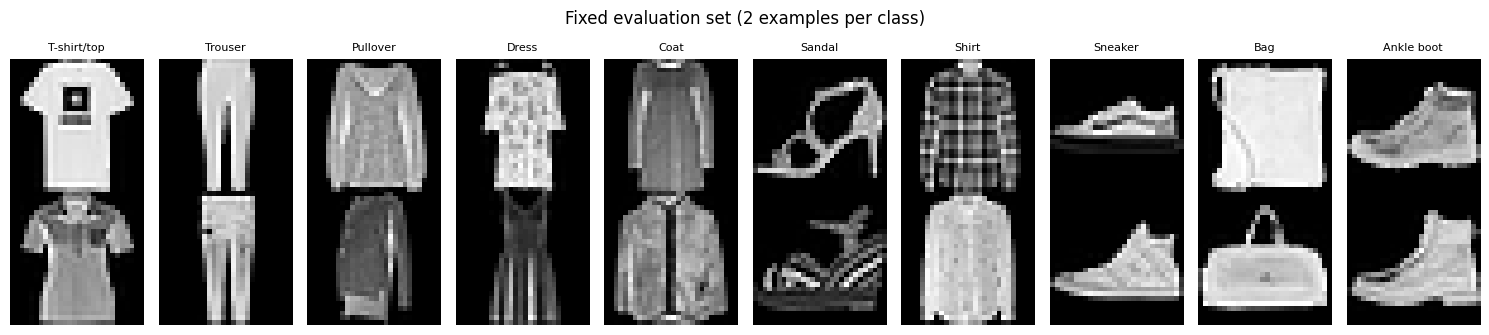

In [6]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    for r in range(2):
        i = np.where(eval_labels == c)[0][r]
        axes[r, c].imshow(eval_images[i]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(class_names[c], fontsize=8)
plt.suptitle("Fixed evaluation set (2 examples per class)"); plt.tight_layout(); plt.show()

## 3. The fine-tuned CLIP from Lab 11 (Part B)

Same recipe as Lab 11 Part B, completed:
- `CLIPClassifier`: CLIP image features (512-d, after `visual_projection`) -> new `nn.Linear(512, 10)`.
- Freeze everything, then unfreeze the last `N_UNFROZEN_BLOCKS = 2` blocks of `vision_model.encoder.layers` and `visual_projection`.
- Adam on trainable params only, `lr = 1e-5`, cross-entropy, `ReduceLROnPlateau`, early stopping on validation loss (patience 3), 80/20 train/val split with seed 42.
- Only addition: mixed precision (`torch.autocast`) to make training faster on a T4. It does not change the method.

For retrieval we do **not** use the classifier head. We use the fine-tuned `clip_model.get_image_features(...)` (moved image space) against the frozen `get_text_features(...)` (unchanged text space). The head is only used to confirm that classification accuracy went up.

In [7]:
class FashionCLIPDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
    def __len__(self):
        return len(self.base_dataset)
    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]
        return image.convert("RGB"), label

def collate_fn(batch):
    images, labels = zip(*batch)
    pixel_values = processor(images=list(images), return_tensors="pt")["pixel_values"]
    return pixel_values, torch.tensor(labels, dtype=torch.long)

train_size = int(0.8 * len(fashion_train_raw))
train_subset, val_subset = random_split(
    fashion_train_raw, [train_size, len(fashion_train_raw) - train_size],
    generator=torch.Generator().manual_seed(42))
if TRAIN_SUBSET is not None:
    train_subset = Subset(train_subset, range(min(TRAIN_SUBSET, len(train_subset))))

loader_kw = dict(batch_size=FT_BATCH, collate_fn=collate_fn, num_workers=NUM_WORKERS)
train_loader = DataLoader(FashionCLIPDataset(train_subset), shuffle=True, **loader_kw)
val_loader = DataLoader(FashionCLIPDataset(val_subset), shuffle=False, **loader_kw)
test_loader = DataLoader(FashionCLIPDataset(fashion_test_raw), shuffle=False, **loader_kw)
print("Train:", len(train_subset), "| Val:", len(val_subset), "| Test:", len(fashion_test_raw))

Train: 48000 | Val: 12000 | Test: 10000


In [8]:
class CLIPClassifier(nn.Module):
    def __init__(self, clip_model, num_classes):
        super().__init__()
        self.clip_model = clip_model
        self.classifier = nn.Linear(clip_model.config.projection_dim, num_classes)

    def forward(self, pixel_values):
        feats = extract_features(self.clip_model.get_image_features(pixel_values=pixel_values))
        return self.classifier(feats.float())


def build_partB_clip():
    m = CLIPModel.from_pretrained(CLIP_ID).to(device)
    for p in m.parameters():
        p.requires_grad = False
    for block in m.vision_model.encoder.layers[-N_UNFROZEN_BLOCKS:]:
        for p in block.parameters():
            p.requires_grad = True
    for p in m.visual_projection.parameters():
        p.requires_grad = True
    return m


def evaluate_classifier(model, data_loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for pv, y in data_loader:
            pv, y = pv.to(device), y.to(device)
            with autocast():
                logits = model(pv)
            total_loss += criterion(logits.float(), y).item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n


def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_with_early_stopping(model, train_loader, val_loader, epochs, patience, lr):
    criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)
    scaler = make_scaler()
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()
        run_loss, correct, n, t0 = 0.0, 0, 0, time.time()
        for pv, y in train_loader:
            pv, y = pv.to(device), y.to(device)
            optimizer.zero_grad()
            with autocast():
                logits = model(pv)
                loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            run_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)

        val_loss, val_acc = evaluate_classifier(model, val_loader)
        scheduler.step(val_loss)
        history["loss"].append(run_loss / n); history["accuracy"].append(correct / n)
        history["val_loss"].append(val_loss); history["val_accuracy"].append(val_acc)
        print(f"Epoch {epoch+1}/{epochs} | loss {run_loss/n:.4f} acc {correct/n:.4f} | "
              f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} | {time.time()-t0:.0f}s")

        if val_loss < best_val:
            best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping."); break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [9]:
clip_ft = build_partB_clip()
model_b = CLIPClassifier(clip_ft, num_classes=len(class_names)).to(device)

trainable = sum(p.numel() for p in model_b.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_b.parameters())
print(f"Part B trainable parameters: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

history_b = None
if LOAD_CHECKPOINT_IF_EXISTS and os.path.exists(CKPT_PATH):
    model_b.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    print("Loaded fine-tuned weights from", CKPT_PATH)
else:
    t0 = time.time()
    history_b = train_with_early_stopping(model_b, train_loader, val_loader,
                                          epochs=FT_EPOCHS, patience=FT_PATIENCE, lr=FT_LR)
    print(f"Part B training time: {time.time()-t0:.0f}s")
    torch.save(model_b.state_dict(), CKPT_PATH)
    json.dump(history_b, open(os.path.join(OUT_DIR, "history_partB.json"), "w"))
    print("Saved ->", CKPT_PATH)

model_b.eval()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Part B trainable parameters: 14,574,090 / 151,282,443 (9.6%)
Epoch 1/5 | loss 0.3689 acc 0.8776 | val_loss 0.2568 val_acc 0.9061 | 187s
Epoch 2/5 | loss 0.2155 acc 0.9220 | val_loss 0.2334 val_acc 0.9144 | 137s
Epoch 3/5 | loss 0.1681 acc 0.9392 | val_loss 0.2164 val_acc 0.9211 | 132s
Epoch 4/5 | loss 0.1245 acc 0.9549 | val_loss 0.2301 val_acc 0.9221 | 131s
Epoch 5/5 | loss 0.0863 acc 0.9696 | val_loss 0.2341 val_acc 0.9224 | 131s
Part B training time: 717s
Saved -> mp3_outputs/clip_partB_finetuned.pt


CLIPClassifier(
  (clip_model): CLIPModel(
    (text_model): CLIPTextModel(
      (embeddings): CLIPTextEmbeddings(
        (token_embedding): Embedding(49408, 512)
        (position_embedding): Embedding(77, 512)
      )
      (encoder): CLIPEncoder(
        (layers): ModuleList(
          (0-11): 12 x CLIPEncoderLayer(
            (self_attn): CLIPAttention(
              (k_proj): Linear(in_features=512, out_features=512, bias=True)
              (v_proj): Linear(in_features=512, out_features=512, bias=True)
              (q_proj): Linear(in_features=512, out_features=512, bias=True)
              (out_proj): Linear(in_features=512, out_features=512, bias=True)
            )
            (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
            (mlp): CLIPMLP(
              (activation_fn): QuickGELUActivation()
              (fc1): Linear(in_features=512, out_features=2048, bias=True)
              (fc2): Linear(in_features=2048, out_features=512, b

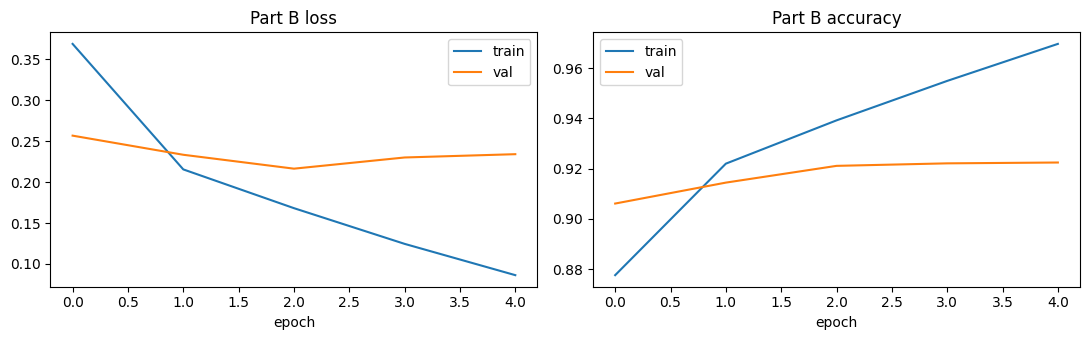

In [10]:
if history_b is not None:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history_b["loss"], label="train"); ax[0].plot(history_b["val_loss"], label="val")
    ax[0].set_title("Part B loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history_b["accuracy"], label="train"); ax[1].plot(history_b["val_accuracy"], label="val")
    ax[1].set_title("Part B accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 4. Cross-modal retrieval system

Two CLIP models share the same API:
- `clip_zs`: a fresh pretrained CLIP, untouched (zero-shot).
- `clip_ft`: the Part B model (moved vision side, frozen text side).

All embeddings are L2-normalised, so the dot product is the cosine similarity.

**Text-to-image.** Each of the 10 class prompts ranks all 1000 eval images. An image is relevant if its class matches the prompt's class. Precision@K = fraction of the top K that are relevant, averaged over the 10 prompts. Because 10 queries is a small sample, we also report **R-precision** (P@100, since each class has 100 relevant images) and **mAP** over the full ranking, which are far more stable.

**Image-to-text.** Each image ranks the 10 prompts. Top-k accuracy = fraction of images whose true class prompt is in the top k (top-1 is exactly zero-shot classification).

In [11]:
@torch.no_grad()
def encode_images(clip_model, pil_images, batch_size=128):
    clip_model.eval()
    out = []
    for i in range(0, len(pil_images), batch_size):
        pv = processor(images=pil_images[i:i+batch_size], return_tensors="pt")["pixel_values"].to(device)
        with autocast():
            f = extract_features(clip_model.get_image_features(pixel_values=pv))
        out.append(F.normalize(f.float(), dim=-1).cpu())
    return torch.cat(out)


@torch.no_grad()
def encode_texts(clip_model, texts):
    clip_model.eval()
    tok = processor(text=texts, return_tensors="pt", padding=True).to(device)
    f = extract_features(clip_model.get_text_features(**tok))
    return F.normalize(f.float(), dim=-1).cpu()


def text_to_image_metrics(text_emb, img_emb, img_labels, ks=(1, 5, 10)):
    """Query c = prompt of class c. Returns averaged metrics and a per-query table."""
    sims = (text_emb @ img_emb.T).numpy()              # (n_queries, n_images)
    order = np.argsort(-sims, axis=1)
    rows = []
    for c in range(sims.shape[0]):
        rel = (img_labels == c)
        ranked_rel = rel[order[c]]
        row = {"query": prompts[c]}
        for k in ks:
            row[f"P@{k}"] = ranked_rel[:k].mean()
        R = rel.sum()
        row["R-precision"] = ranked_rel[:R].mean()
        row["AP"] = average_precision_score(rel.astype(int), sims[c])
        rows.append(row)
    per_query = pd.DataFrame(rows)
    summary = per_query.drop(columns="query").mean().rename({"AP": "mAP"}).to_dict()
    return summary, per_query


def image_to_text_metrics(img_emb, text_emb, img_labels, ks=(1, 3, 5)):
    sims = img_emb @ text_emb.T                       # (n_images, n_classes)
    topk = sims.topk(max(ks), dim=1).indices.numpy()
    res = {f"top-{k}": (topk[:, :k] == img_labels[:, None]).any(1).mean() for k in ks}
    return res, sims.argmax(1).numpy()


def image_to_image_metrics(img_emb, img_labels, ks=(1, 5, 10)):
    sims = (img_emb @ img_emb.T).numpy()
    np.fill_diagonal(sims, -np.inf)                   # never retrieve the query itself
    order = np.argsort(-sims, axis=1)
    res = {f"P@{k}": (img_labels[order[:, :k]] == img_labels[:, None]).mean() for k in ks}
    aps = []
    for q in range(len(img_labels)):
        mask = np.arange(len(img_labels)) != q
        aps.append(average_precision_score((img_labels[mask] == img_labels[q]).astype(int), sims[q][mask]))
    res["mAP"] = float(np.mean(aps))
    return res

In [12]:
clip_zs = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
clip_ft = model_b.clip_model.eval()

# Sanity check: the text side of the fine-tuned model must be bit-identical to the zero-shot one
text_same = all(torch.equal(a, b) for a, b in zip(clip_zs.text_model.parameters(), clip_ft.text_model.parameters()))
proj_same = torch.equal(clip_zs.text_projection.weight, clip_ft.text_projection.weight)
vis_changed = not torch.equal(clip_zs.visual_projection.weight, clip_ft.visual_projection.weight)
print("Text encoder unchanged:", text_same, "| text_projection unchanged:", proj_same,
      "| visual_projection changed:", vis_changed)

text_emb_zs = encode_texts(clip_zs, prompts)
text_emb_ft = encode_texts(clip_ft, prompts)
print("Max |text_zs - text_ft|:", (text_emb_zs - text_emb_ft).abs().max().item())
text_emb = text_emb_zs  # identical for both models

t0 = time.time()
img_emb_zs = encode_images(clip_zs, eval_images)
img_emb_ft = encode_images(clip_ft, eval_images)
print("Image embeddings:", tuple(img_emb_zs.shape), tuple(img_emb_ft.shape), f"| {time.time()-t0:.0f}s")
torch.save({"img_emb_zs": img_emb_zs, "img_emb_ft": img_emb_ft, "text_emb": text_emb,
            "eval_labels": eval_labels}, os.path.join(OUT_DIR, "eval_embeddings.pt"))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Text encoder unchanged: True | text_projection unchanged: True | visual_projection changed: True
Max |text_zs - text_ft|: 0.0
Image embeddings: (1000, 512) (1000, 512) | 4s


In [13]:
t2i_zs, t2i_zs_q = text_to_image_metrics(text_emb, img_emb_zs, eval_labels)
t2i_ft, t2i_ft_q = text_to_image_metrics(text_emb, img_emb_ft, eval_labels)
i2t_zs, pred_zs = image_to_text_metrics(img_emb_zs, text_emb, eval_labels)
i2t_ft, pred_ft = image_to_text_metrics(img_emb_ft, text_emb, eval_labels)
i2i_zs = image_to_image_metrics(img_emb_zs, eval_labels)
i2i_ft = image_to_image_metrics(img_emb_ft, eval_labels)

# Classification accuracy of the trained head, on the same 1000 images and on the full test set
with torch.no_grad():
    head_preds = []
    for i in range(0, len(eval_images), 128):
        pv = processor(images=eval_images[i:i+128], return_tensors="pt")["pixel_values"].to(device)
        with autocast():
            head_preds.append(model_b(pv).argmax(1).cpu())
    head_preds = torch.cat(head_preds).numpy()
head_acc_eval = (head_preds == eval_labels).mean()
_, head_acc_full_test = evaluate_classifier(model_b, test_loader)
print(f"Part B head accuracy | eval set: {head_acc_eval:.4f} | full test set (10k): {head_acc_full_test:.4f}")

Part B head accuracy | eval set: 0.9230 | full test set (10k): 0.9179


## 5. Zero-shot vs fine-tuned: comparison table

In [14]:
def row(task, metric, zs, ft):
    return {"Task": task, "Metric": metric, "Zero-shot CLIP": zs, "Fine-tuned CLIP (Part B)": ft, "Delta (FT - ZS)": ft - zs}

rows = []
for m in ["P@1", "P@5", "P@10", "R-precision", "mAP"]:
    rows.append(row("Text -> image", m, t2i_zs[m], t2i_ft[m]))
for m in ["top-1", "top-3", "top-5"]:
    rows.append(row("Image -> text", m, i2t_zs[m], i2t_ft[m]))
rows.append(row("Classification", "accuracy (ZS prompts vs FT head)", i2t_zs["top-1"], head_acc_eval))
for m in ["P@1", "P@5", "P@10", "mAP"]:
    rows.append(row("Image -> image", m, i2i_zs[m], i2i_ft[m]))

results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUT_DIR, "results_fashionmnist.csv"), index=False)
results.style.format({c: "{:.3f}" for c in ["Zero-shot CLIP", "Fine-tuned CLIP (Part B)", "Delta (FT - ZS)"]}) \
    .background_gradient(subset=["Delta (FT - ZS)"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)

,Task,Metric,Zero-shot CLIP,Fine-tuned CLIP (Part B),Delta (FT - ZS)
0,Text -> image,P@1,0.900,0.100,-0.800
1,Text -> image,P@5,0.820,0.120,-0.700
2,Text -> image,P@10,0.770,0.110,-0.660
3,Text -> image,R-precision,0.562,0.138,-0.424
4,Text -> image,mAP,0.607,0.211,-0.396
5,Image -> text,top-1,0.625,0.320,-0.305
6,Image -> text,top-3,0.892,0.639,-0.253
7,Image -> text,top-5,0.972,0.892,-0.080
8,Classification,accuracy (ZS prompts vs FT head),0.625,0.923,0.298
9,Image -> image,P@1,0.786,0.895,0.109


In [15]:
print("Per-query text-to-image results")
per_q = t2i_zs_q[["query", "P@10", "R-precision", "AP"]].merge(
    t2i_ft_q[["query", "P@10", "R-precision", "AP"]], on="query", suffixes=(" ZS", " FT"))
display(per_q.round(3))

Per-query text-to-image results


,query,P@10 ZS,R-precision ZS,AP ZS,P@10 FT,R-precision FT,AP FT
0,a photo of a T-shirt/top,0.9,0.58,0.598,0.0,0.15,0.205
1,a photo of a Trouser,1.0,0.80,0.892,0.0,0.00,0.057
2,a photo of a Pullover,0.6,0.49,0.492,1.0,0.81,0.869
3,a photo of a Dress,0.8,0.56,0.603,0.0,0.06,0.137
4,a photo of a Coat,0.5,0.39,0.408,0.0,0.08,0.181
5,a photo of a Sandal,0.6,0.25,0.293,0.0,0.00,0.089
6,a photo of a Shirt,0.3,0.33,0.316,0.1,0.22,0.274
7,a photo of a Sneaker,1.0,0.68,0.744,0.0,0.00,0.113
8,a photo of a Bag,1.0,0.69,0.799,0.0,0.00,0.055
9,a photo of a Ankle boot,1.0,0.85,0.928,0.0,0.06,0.127


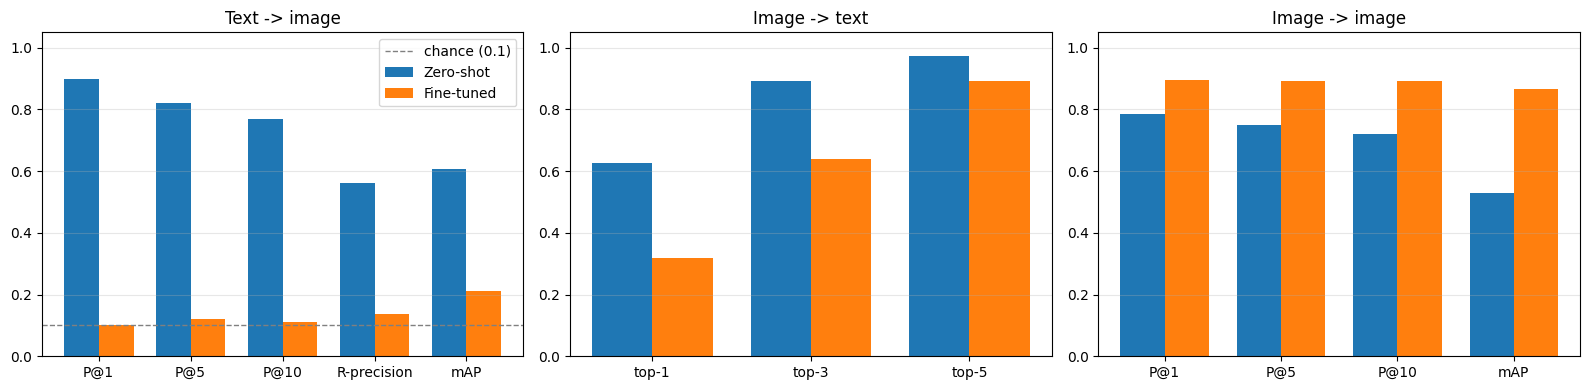

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
groups = [("Text -> image", ["P@1", "P@5", "P@10", "R-precision", "mAP"]),
          ("Image -> text", ["top-1", "top-3", "top-5"]),
          ("Image -> image", ["P@1", "P@5", "P@10", "mAP"])]
for ax, (task, metrics) in zip(axes, groups):
    sub = results[results["Task"] == task].set_index("Metric").loc[metrics]
    x = np.arange(len(metrics)); w = 0.38
    ax.bar(x - w/2, sub["Zero-shot CLIP"], w, label="Zero-shot")
    ax.bar(x + w/2, sub["Fine-tuned CLIP (Part B)"], w, label="Fine-tuned")
    ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0, 1.05); ax.set_title(task)
    ax.grid(axis="y", alpha=.3)
axes[0].axhline(0.1, ls="--", c="grey", lw=1, label="chance (0.1)")
axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "retrieval_comparison.png"), dpi=150); plt.show()

**Visual check of text-to-image retrieval** (top 8 images per prompt, green border = correct class).

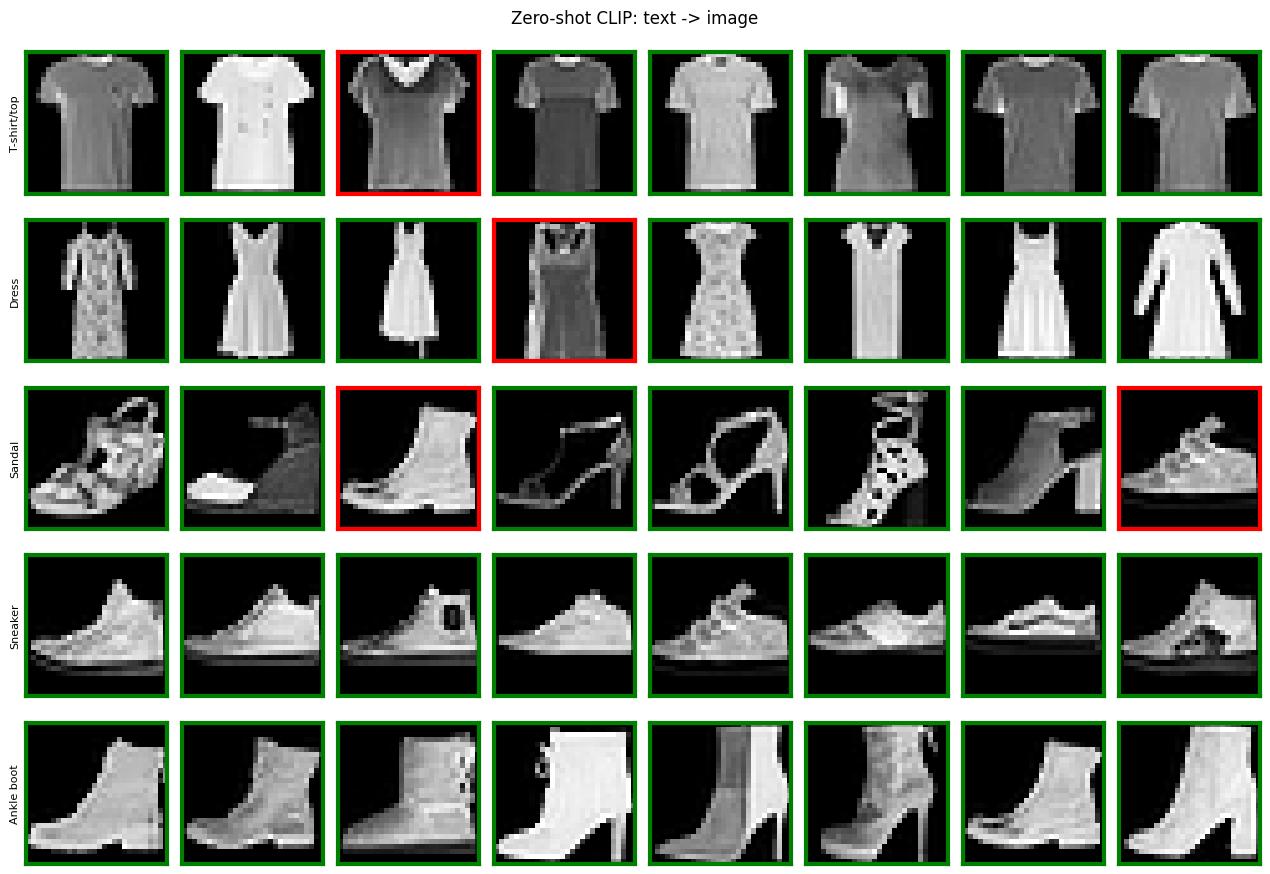

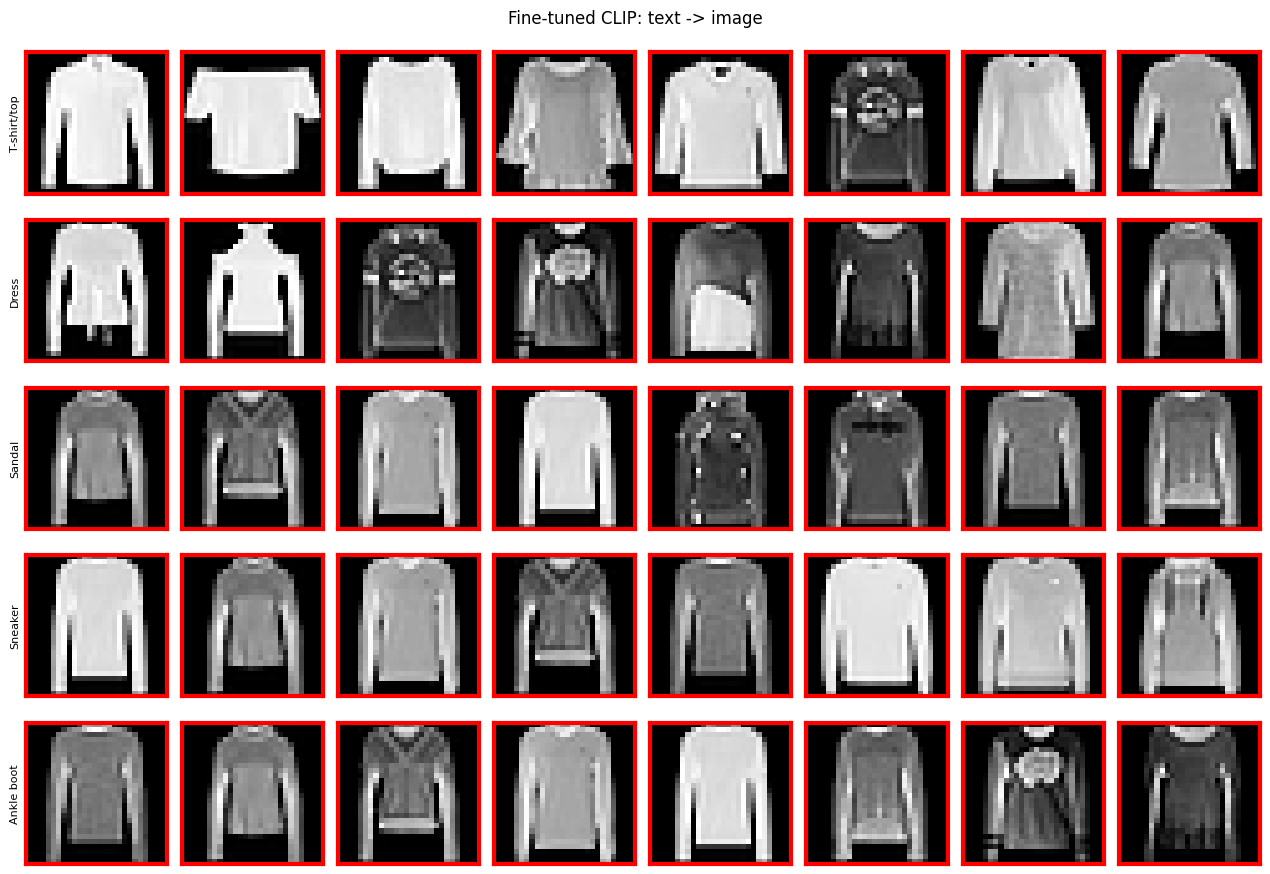

In [17]:
def show_t2i(img_emb, title, query_classes=(0, 3, 5, 7, 9), k=8):
    sims = (text_emb @ img_emb.T).numpy()
    fig, axes = plt.subplots(len(query_classes), k, figsize=(1.6*k, 1.8*len(query_classes)))
    for r, c in enumerate(query_classes):
        top = np.argsort(-sims[c])[:k]
        for j, i in enumerate(top):
            ax = axes[r, j]; ax.imshow(eval_images[i]); ax.set_xticks([]); ax.set_yticks([])
            color = "green" if eval_labels[i] == c else "red"
            for s in ax.spines.values(): s.set_edgecolor(color); s.set_linewidth(3)
            if j == 0: ax.set_ylabel(class_names[c], fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_t2i(img_emb_zs, "Zero-shot CLIP: text -> image")
show_t2i(img_emb_ft, "Fine-tuned CLIP: text -> image")

## 6. How far did fine-tuning move the image embedding space?

Task-independent measurement: for each of the 1000 eval images, `cos(e_zs(x), e_ft(x))` between its zero-shot and fine-tuned image embedding. A value of 1 means unchanged; values far below 1 mean the image now sits somewhere else on the sphere.

To make the number interpretable, we put it next to two reference scales measured in the zero-shot space: the average cosine between two **different images of the same class**, and between images of **different classes**. We also measure what matters for retrieval: the cosine between each image and **its own class prompt**, and the margin over the best wrong prompt.

In [18]:
drift = (img_emb_zs * img_emb_ft).sum(1).numpy()

def mean_offdiag(sim, mask):
    return sim[mask].mean()

S_zs = (img_emb_zs @ img_emb_zs.T).numpy()
same = eval_labels[:, None] == eval_labels[None, :]
np.fill_diagonal(same, False)
diff = eval_labels[:, None] != eval_labels[None, :]

own_zs = (img_emb_zs @ text_emb.T).numpy()
own_ft = (img_emb_ft @ text_emb.T).numpy()
idx = np.arange(len(eval_labels))
def margin(sim):
    true = sim[idx, eval_labels]
    other = sim.copy(); other[idx, eval_labels] = -np.inf
    return true - other.max(1)

def modality_gap(img_emb):
    return (img_emb.mean(0) - text_emb.mean(0)).norm().item()

drift_stats = {
    "cos(ZS, FT) same image: mean": drift.mean(),
    "cos(ZS, FT) same image: std": drift.std(),
    "cos(ZS, FT) same image: min": drift.min(),
    "cos(ZS, FT) same image: median": np.median(drift),
    "Ref: ZS cos, same class, different images": mean_offdiag(S_zs, same),
    "Ref: ZS cos, different classes": mean_offdiag(S_zs, diff),
    "cos(image, own prompt) ZS": own_zs[idx, eval_labels].mean(),
    "cos(image, own prompt) FT": own_ft[idx, eval_labels].mean(),
    "margin own vs best wrong prompt ZS": margin(own_zs).mean(),
    "margin own vs best wrong prompt FT": margin(own_ft).mean(),
    "modality gap ||mean(img) - mean(txt)|| ZS": modality_gap(img_emb_zs),
    "modality gap ||mean(img) - mean(txt)|| FT": modality_gap(img_emb_ft),
}
drift_df = pd.DataFrame.from_dict(drift_stats, orient="index", columns=["value"])
drift_df.to_csv(os.path.join(OUT_DIR, "embedding_drift.csv"))
display(drift_df.round(4))

per_class_drift = pd.DataFrame({"class": class_names,
                                "mean cos(ZS, FT)": [drift[eval_labels == c].mean() for c in range(10)],
                                "cos(img, own prompt) ZS": [own_zs[eval_labels == c, c].mean() for c in range(10)],
                                "cos(img, own prompt) FT": [own_ft[eval_labels == c, c].mean() for c in range(10)]})
display(per_class_drift.round(4))

,value
"cos(ZS, FT) same image: mean",0.2752
"cos(ZS, FT) same image: std",0.0437
"cos(ZS, FT) same image: min",0.1488
"cos(ZS, FT) same image: median",0.2735
"Ref: ZS cos, same class, different images",0.9202
"Ref: ZS cos, different classes",0.8680
"cos(image, own prompt) ZS",0.2694
"cos(image, own prompt) FT",0.1448
margin own vs best wrong prompt ZS,0.0059
margin own vs best wrong prompt FT,-0.0067


,class,"mean cos(ZS, FT)","cos(img, own prompt) ZS","cos(img, own prompt) FT"
0,T-shirt/top,0.2924,0.2678,0.1963
1,Trouser,0.2611,0.2781,0.0758
2,Pullover,0.3129,0.2966,0.2013
3,Dress,0.2776,0.2641,0.1586
4,Coat,0.2166,0.2599,0.1794
5,Sandal,0.3044,0.2464,0.1129
6,Shirt,0.2878,0.2551,0.1990
7,Sneaker,0.2498,0.2769,0.1271
8,Bag,0.2903,0.2673,0.0681
9,Ankle boot,0.2587,0.2822,0.1290


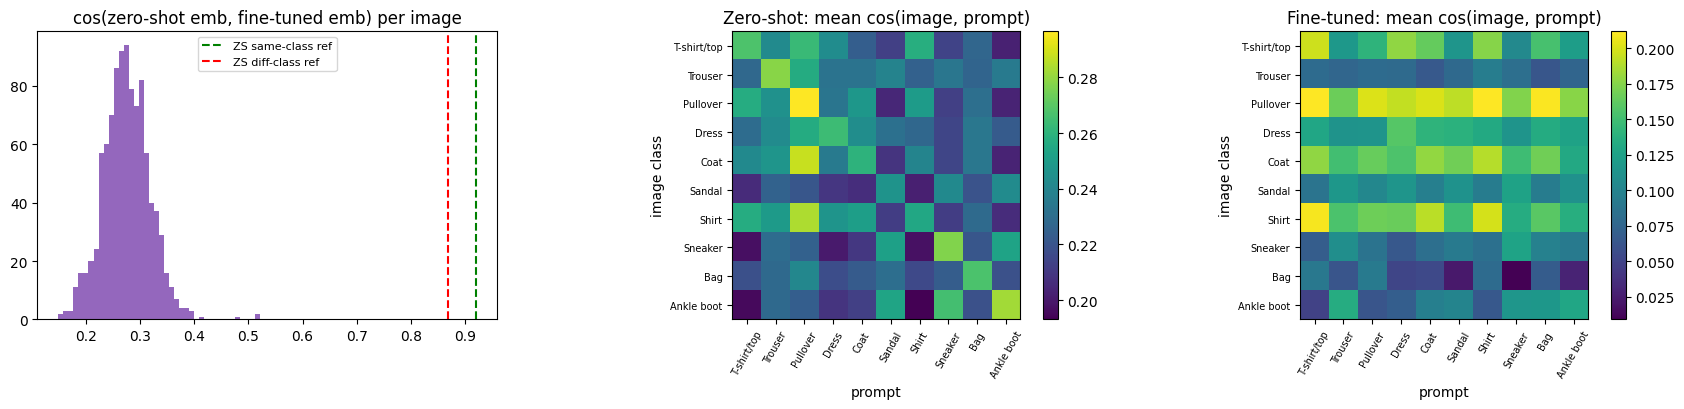

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(drift, bins=40, color="tab:purple")
axes[0].axvline(drift_stats["Ref: ZS cos, same class, different images"], c="green", ls="--", label="ZS same-class ref")
axes[0].axvline(drift_stats["Ref: ZS cos, different classes"], c="red", ls="--", label="ZS diff-class ref")
axes[0].set_title("cos(zero-shot emb, fine-tuned emb) per image"); axes[0].legend(fontsize=8)

def class_prompt_matrix(sim):
    return np.stack([sim[eval_labels == c].mean(0) for c in range(10)])

for ax, sim, name in [(axes[1], own_zs, "Zero-shot"), (axes[2], own_ft, "Fine-tuned")]:
    m = class_prompt_matrix(sim)
    im = ax.imshow(m, cmap="viridis")
    ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation=60, fontsize=7)
    ax.set_yticks(range(10)); ax.set_yticklabels(class_names, fontsize=7)
    ax.set_xlabel("prompt"); ax.set_ylabel("image class")
    ax.set_title(f"{name}: mean cos(image, prompt)"); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "embedding_drift.png"), dpi=150); plt.show()

**How to read this section**
- If the mean `cos(ZS, FT)` for the *same* image is below the zero-shot same-class reference, fine-tuning moved images further than the typical distance between two different shirts in the original space: a large move.
- A bright diagonal in the zero-shot heatmap that fades (or shifts off-diagonal) after fine-tuning is the direct picture of broken alignment: the images moved, the prompts did not.

## 7. Real product photos: attribute queries on fashion product photos

**Dataset choice.** `ceyda/fashion-products-small` (named in the brief as an example) only has `masterCategory`, `gender` and `subCategory` as metadata, with **no colour column**, so colour queries like "a red dress" cannot be judged from it. We therefore use `ashraq/fashion-product-images-small`, built from the same Kaggle *Fashion Product Images* catalogue, which keeps `baseColour` and `articleType`. If that dataset cannot be loaded, the code falls back to `ceyda/fashion-products-small` and judges **category only** (`subCategory`), and says so.

- Gallery: `N_GALLERY = 5000` photos sampled with `SEED = 42` (fixed, metadata saved to CSV).
- 12 attribute queries combining a **colour** and a **category**. Ground truth comes from the metadata columns (`baseColour`, `articleType`), not from our judgement.
- For each query and each model we retrieve the top 5 and report three precisions: colour correct, category correct, both correct (strict).
- The query only judges attributes present in the metadata (e.g. "leather" in "a brown leather wallet" is not judged, only brown + wallet).
- Before evaluating, we print how many gallery items satisfy each query so we never score a query that has fewer than 5 possible hits.

In [20]:
from datasets import load_dataset

COLOUR_NAMES = ("baseColour", "basecolor", "colour", "color")
# Tried in order: the first one that loads AND has a colour column wins.
PRODUCT_DATASETS = ["ashraq/fashion-product-images-small", "ceyda/fashion-products-small"]

fp_full, PRODUCT_DS = None, None
for name in PRODUCT_DATASETS:
    try:
        ds = load_dataset(name, split="train")
    except Exception as e:
        print(f"Could not load {name}: {type(e).__name__}: {str(e)[:200]}")
        continue
    has_colour = any(c.lower() in {n.lower() for n in COLOUR_NAMES} for c in ds.column_names)
    print(f"{name}: {ds.num_rows} rows | columns: {ds.column_names} | colour column: {has_colour}")
    if fp_full is None or has_colour:
        fp_full, PRODUCT_DS = ds, name
    if has_colour:
        break
assert fp_full is not None, "No product dataset could be loaded (check the internet connection of the runtime)."
print("Using dataset:", PRODUCT_DS)

IMAGE_COL = next(c for c in fp_full.column_names if c.lower() in ("image", "img"))
fp = fp_full.shuffle(seed=SEED).select(range(min(N_GALLERY, len(fp_full))))
meta = fp.remove_columns([IMAGE_COL]).to_pandas()

def find_col(df, *candidates, required=True):
    low = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    if required:
        raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

COLOR_COL = find_col(meta, *COLOUR_NAMES, required=False)
TYPE_COL = find_col(meta, "articleType", "article_type", "subCategory")
HAS_COLOUR = COLOR_COL is not None
TYPE_LEVEL = "articleType" if TYPE_COL.lower() in ("articletype", "article_type") else "subCategory"
print("Using metadata columns | colour:", COLOR_COL, "| category:", TYPE_COL)
if not HAS_COLOUR:
    print("NOTE: no colour metadata -> queries are judged on CATEGORY ONLY.")
meta["_color"] = meta[COLOR_COL].astype(str).str.strip().str.lower() if HAS_COLOUR else ""
meta["_type"] = meta[TYPE_COL].astype(str).str.strip().str.lower()
meta.to_csv(os.path.join(OUT_DIR, "fashion_products_gallery_meta.csv"), index=False)

gallery_images = [im.convert("RGB") for im in fp[IMAGE_COL]]
print("Gallery size:", len(gallery_images))
if HAS_COLOUR:
    print("Top colours:", meta["_color"].value_counts().head(12).to_dict())
print("Top article types:", meta["_type"].value_counts().head(20).to_dict())

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

ashraq/fashion-product-images-small: 44072 rows | columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image'] | colour column: True
Using dataset: ashraq/fashion-product-images-small
Using metadata columns | colour: baseColour | category: articleType
Gallery size: 5000
Top colours: {'black': 1058, 'white': 662, 'blue': 546, 'brown': 371, 'grey': 318, 'red': 299, 'green': 248, 'navy blue': 232, 'pink': 188, 'purple': 180, 'silver': 125, 'yellow': 92}
Top article types: {'tshirts': 771, 'shirts': 350, 'casual shoes': 312, 'watches': 271, 'sports shoes': 255, 'kurtas': 222, 'handbags': 184, 'tops': 179, 'heels': 160, 'sunglasses': 127, 'flip flops': 109, 'wallets': 107, 'sandals': 107, 'belts': 95, 'briefs': 84, 'formal shoes': 77, 'socks': 76, 'jeans': 72, 'backpacks': 71, 'shorts': 69}


In [21]:
# (query text, accepted colours, accepted articleType values, accepted subCategory values)
# All lower-case, matched exactly. The subCategory list is only used if the dataset has no articleType.
QUERY_SPECS = [
    ("a black handbag",                 ["black"],                 ["handbags"],     ["bags"]),
    ("a red dress",                     ["red"],                   ["dresses"],      ["dress"]),
    ("a blue t-shirt",                  ["blue", "navy blue"],     ["tshirts"],      ["topwear"]),
    ("a pair of white sports shoes",    ["white"],                 ["sports shoes"], ["shoes"]),
    ("a brown leather wallet",          ["brown"],                 ["wallets"],      ["wallets"]),
    ("a pair of black sunglasses",      ["black"],                 ["sunglasses"],   ["eyewear"]),
    ("a pink top",                      ["pink"],                  ["tops"],         ["topwear"]),
    ("a silver watch",                  ["silver"],                ["watches"],      ["watches"]),
    ("a pair of blue jeans",            ["blue", "navy blue"],     ["jeans"],        ["bottomwear"]),
    ("a black backpack",                ["black"],                 ["backpacks"],    ["bags"]),
    ("a pair of brown sandals",         ["brown"],                 ["sandals"],      ["sandal"]),
    ("a grey sweatshirt",               ["grey", "grey melange"],  ["sweatshirts"],  ["topwear"]),
]
QUERIES = [(q, cols, art if TYPE_LEVEL == "articleType" else sub) for q, cols, art, sub in QUERY_SPECS]

def colour_ok(rows_color, colors):
    # without colour metadata every item counts as colour-correct, so "both" == "category"
    return rows_color.isin(colors) if HAS_COLOUR else pd.Series(True, index=rows_color.index)

avail = []
for q, colors, types in QUERIES:
    c_ok = colour_ok(meta["_color"], colors); t_ok = meta["_type"].isin(types)
    avail.append({"query": q, "#colour": int(c_ok.sum()) if HAS_COLOUR else None,
                  "#category": int(t_ok.sum()), "#both": int((c_ok & t_ok).sum())})
avail = pd.DataFrame(avail)
display(avail)
valid_queries = [Q for Q, n in zip(QUERIES, avail["#both"]) if n >= 5]
print(f"{len(valid_queries)}/{len(QUERIES)} queries have >= 5 fully relevant items in the gallery and are scored.")
if len(valid_queries) < 10:
    print("WARNING: fewer than 10 scorable queries. Increase N_GALLERY in the config cell, "
          "or edit QUERY_SPECS using the counts above.")

,query,#colour,#category,#both
0,a black handbag,1058,184,38
1,a red dress,299,53,3
2,a blue t-shirt,778,771,171
3,a pair of white sports shoes,662,255,119
4,a brown leather wallet,371,107,35
5,a pair of black sunglasses,1058,127,42
6,a pink top,188,179,16
7,a silver watch,125,271,37
8,a pair of blue jeans,778,72,54
9,a black backpack,1058,71,19


11/12 queries have >= 5 fully relevant items in the gallery and are scored.


In [22]:
t0 = time.time()
gal_emb_zs = encode_images(clip_zs, gallery_images)
gal_emb_ft = encode_images(clip_ft, gallery_images)
print(f"Gallery encoded in {time.time()-t0:.0f}s")
q_texts = [q for q, _, _ in valid_queries]
q_emb = encode_texts(clip_zs, q_texts)   # text side identical for both models

def attribute_eval(gal_emb, k=5):
    sims = (q_emb @ gal_emb.T).numpy()
    rows, tops = [], []
    for qi, (q, colors, types) in enumerate(valid_queries):
        top = np.argsort(-sims[qi])[:k]; tops.append(top)
        c_ok = colour_ok(meta["_color"].iloc[top], colors).values
        t_ok = meta["_type"].iloc[top].isin(types).values
        rows.append({"query": q, "colour P@5": c_ok.mean() if HAS_COLOUR else np.nan,
                     "category P@5": t_ok.mean(), "both P@5": (c_ok & t_ok).mean()})
    return pd.DataFrame(rows), tops

attr_zs, tops_zs = attribute_eval(gal_emb_zs)
attr_ft, tops_ft = attribute_eval(gal_emb_ft)
attr = attr_zs.merge(attr_ft, on="query", suffixes=(" | ZS", " | FT"))
num_cols = ["colour P@5 | ZS", "colour P@5 | FT", "category P@5 | ZS", "category P@5 | FT",
            "both P@5 | ZS", "both P@5 | FT"]
attr = attr[["query"] + num_cols]
mean_row = pd.DataFrame([{"query": "MEAN", **attr[num_cols].mean().to_dict()}])
attr = pd.concat([attr, mean_row], ignore_index=True)
attr[num_cols] = attr[num_cols].astype(float)
if not HAS_COLOUR:
    attr = attr.drop(columns=["colour P@5 | ZS", "colour P@5 | FT"])
attr.to_csv(os.path.join(OUT_DIR, "results_fashion_products.csv"), index=False)
print(f"Dataset: {PRODUCT_DS} | relevance judged on: {'colour + ' if HAS_COLOUR else ''}{TYPE_COL}")
display(attr.set_index("query").round(2))

prod_drift = (gal_emb_zs * gal_emb_ft).sum(1).numpy()
print(f"Embedding drift on real photos: mean cos(ZS, FT) = {prod_drift.mean():.4f} "
      f"(FashionMNIST eval set: {drift.mean():.4f})")

Gallery encoded in 24s
Dataset: ashraq/fashion-product-images-small | relevance judged on: colour + articleType


,colour P@5 | ZS,colour P@5 | FT,category P@5 | ZS,category P@5 | FT,both P@5 | ZS,both P@5 | FT
query,,,,,,
a black handbag,1.00,0.80,1.00,0.00,1.00,0.00
a blue t-shirt,1.00,1.00,0.60,1.00,0.60,1.00
a pair of white sports shoes,1.00,0.60,0.80,0.20,0.80,0.20
a brown leather wallet,1.00,1.00,1.00,1.00,1.00,1.00
a pair of black sunglasses,0.60,0.40,1.00,1.00,0.60,0.40
a pink top,0.60,0.80,0.60,0.60,0.40,0.40
a silver watch,0.00,0.20,0.80,0.80,0.00,0.20
a pair of blue jeans,1.00,0.80,1.00,0.80,1.00,0.80
a black backpack,1.00,0.80,1.00,0.80,1.00,0.60


Embedding drift on real photos: mean cos(ZS, FT) = 0.6194 (FashionMNIST eval set: 0.2752)


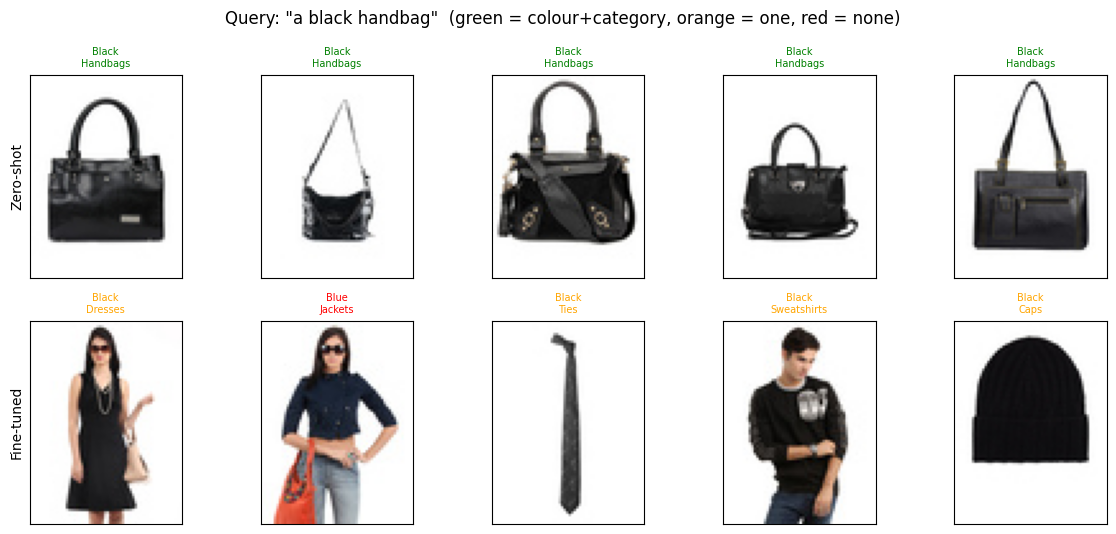

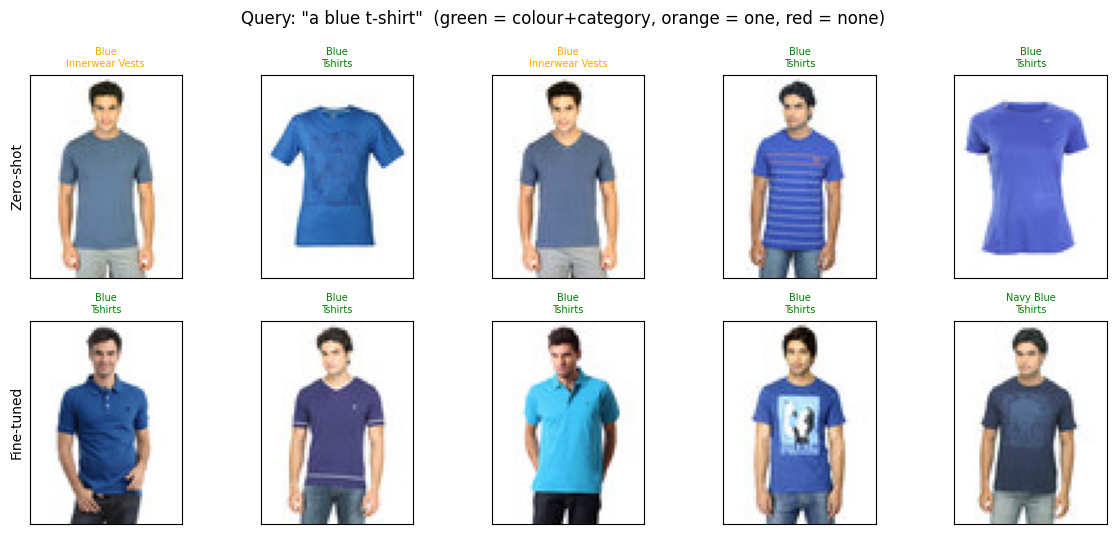

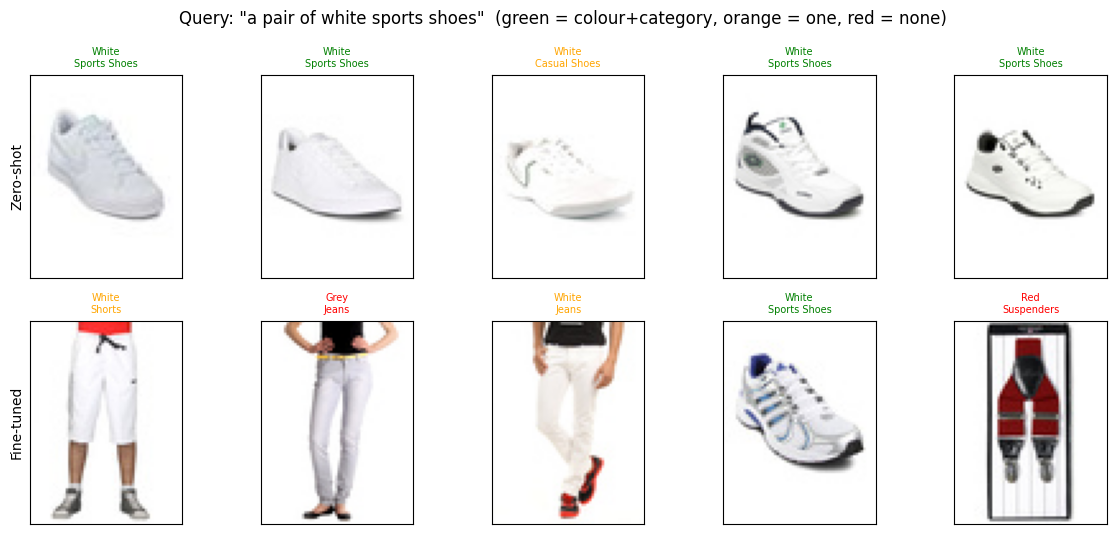

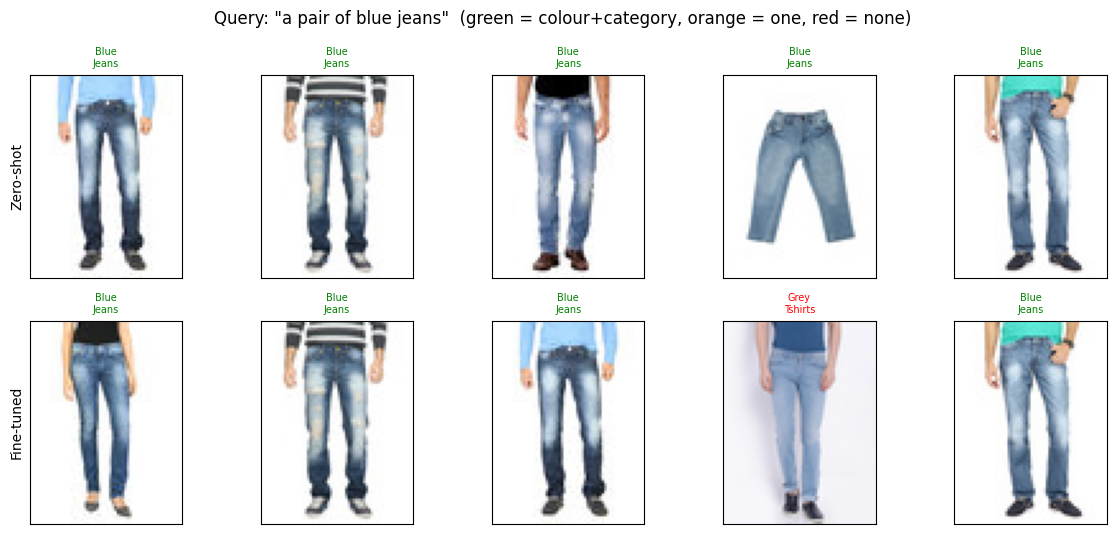

In [23]:
def show_attr(qi_list):
    for qi in qi_list:
        q, colors, types = valid_queries[qi]
        fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
        for r, (tops, name) in enumerate([(tops_zs, "Zero-shot"), (tops_ft, "Fine-tuned")]):
            for j, gi in enumerate(tops[qi]):
                ax = axes[r, j]; ax.imshow(gallery_images[gi]); ax.set_xticks([]); ax.set_yticks([])
                c_ok = (meta["_color"].iloc[gi] in colors) if HAS_COLOUR else True
                t_ok = meta["_type"].iloc[gi] in types
                colour_txt = meta[COLOR_COL].iloc[gi] if HAS_COLOUR else "-"
                ax.set_title(f"{colour_txt}\n{meta[TYPE_COL].iloc[gi]}", fontsize=7,
                             color="green" if (c_ok and t_ok) else ("orange" if (c_ok or t_ok) else "red"))
                if j == 0: ax.set_ylabel(name)
        plt.suptitle(f'Query: "{q}"  (green = colour+category, orange = one, red = none)')
        plt.tight_layout(); plt.show()

show_attr([0, 1, 2, 7])

## 8. Optional extension: image-to-image retrieval in four embedding spaces

Same fixed 1000-image eval set, each image is a query against the other 999, relevance = same class. Spaces:
1. CLIP zero-shot image embeddings (512-d)
2. CLIP fine-tuned (Part B) image embeddings (512-d)
3. Pretrained ViT `vit_b_32` (torchvision, ImageNet) with the classification head removed (768-d)
4. Convolutional autoencoder latent vectors (trained here on FashionMNIST train, 128-d)

**Limitation (stated explicitly as the brief asks):** the dimensions differ (512 / 768 / 128), so this is not a capacity-matched comparison. The AE is also trained for reconstruction only, on 28x28 inputs.

In [24]:
if RUN_EXTENSION:
    from torchvision.models import vit_b_32, ViT_B_32_Weights
    from sklearn.manifold import TSNE

    # --- ViT-B/32 without head
    vit_weights = ViT_B_32_Weights.IMAGENET1K_V1
    vit = vit_b_32(weights=vit_weights).to(device).eval()
    vit.heads = nn.Identity()
    vit_tf = vit_weights.transforms()

    @torch.no_grad()
    def encode_vit(pil_images, bs=128):
        out = []
        for i in range(0, len(pil_images), bs):
            x = torch.stack([vit_tf(im) for im in pil_images[i:i+bs]]).to(device)
            with autocast():
                f = vit(x)
            out.append(F.normalize(f.float(), dim=-1).cpu())
        return torch.cat(out)

    emb_vit = encode_vit(eval_images)

    # --- Conv autoencoder (Lab 3 style)
    class ConvAE(nn.Module):
        def __init__(self, latent_dim=128):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
                nn.Flatten(), nn.Linear(64 * 7 * 7, latent_dim))
            self.decoder = nn.Sequential(
                nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU(), nn.Unflatten(1, (64, 7, 7)),
                nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
                nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid())
        def forward(self, x):
            return self.decoder(self.encoder(x))

    ae_train = datasets.FashionMNIST("./data", train=True, download=True, transform=transforms.ToTensor())
    ae_loader = DataLoader(ae_train, batch_size=256, shuffle=True, num_workers=NUM_WORKERS)
    seed_everything()
    ae = ConvAE(128).to(device)
    ae_opt = optim.Adam(ae.parameters(), lr=1e-3)
    for ep in range(5):
        ae.train(); tot = 0
        for x, _ in ae_loader:
            x = x.to(device); ae_opt.zero_grad()
            loss = F.mse_loss(ae(x), x); loss.backward(); ae_opt.step()
            tot += loss.item() * x.size(0)
        print(f"AE epoch {ep+1}/5 | MSE {tot/len(ae_train):.5f}")
    ae.eval()
    with torch.no_grad():
        x_eval = torch.stack([transforms.ToTensor()(fashion_test_raw[int(i)][0]) for i in eval_idx]).to(device)
        emb_ae = F.normalize(ae.encoder(x_eval), dim=-1).cpu()

    spaces = {"CLIP zero-shot (512-d)": img_emb_zs, "CLIP fine-tuned (512-d)": img_emb_ft,
              "ViT-B/32 ImageNet (768-d)": emb_vit, "Conv AE latent (128-d)": emb_ae}
    ext = pd.DataFrame({name: image_to_image_metrics(e, eval_labels) for name, e in spaces.items()}).T
    ext["Answers text queries?"] = ["yes", "yes (degraded?)", "no", "no"]
    ext.to_csv(os.path.join(OUT_DIR, "results_image_to_image.csv"))
    display(ext.round(3))

Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:07<00:00, 45.5MB/s]


AE epoch 1/5 | MSE 0.03059
AE epoch 2/5 | MSE 0.01154
AE epoch 3/5 | MSE 0.00889
AE epoch 4/5 | MSE 0.00753
AE epoch 5/5 | MSE 0.00664


,P@1,P@5,P@10,mAP,Answers text queries?
CLIP zero-shot (512-d),0.786,0.749,0.720,0.528,yes
CLIP fine-tuned (512-d),0.895,0.894,0.891,0.867,yes (degraded?)
ViT-B/32 ImageNet (768-d),0.812,0.778,0.750,0.578,no
Conv AE latent (128-d),0.790,0.753,0.716,0.509,no


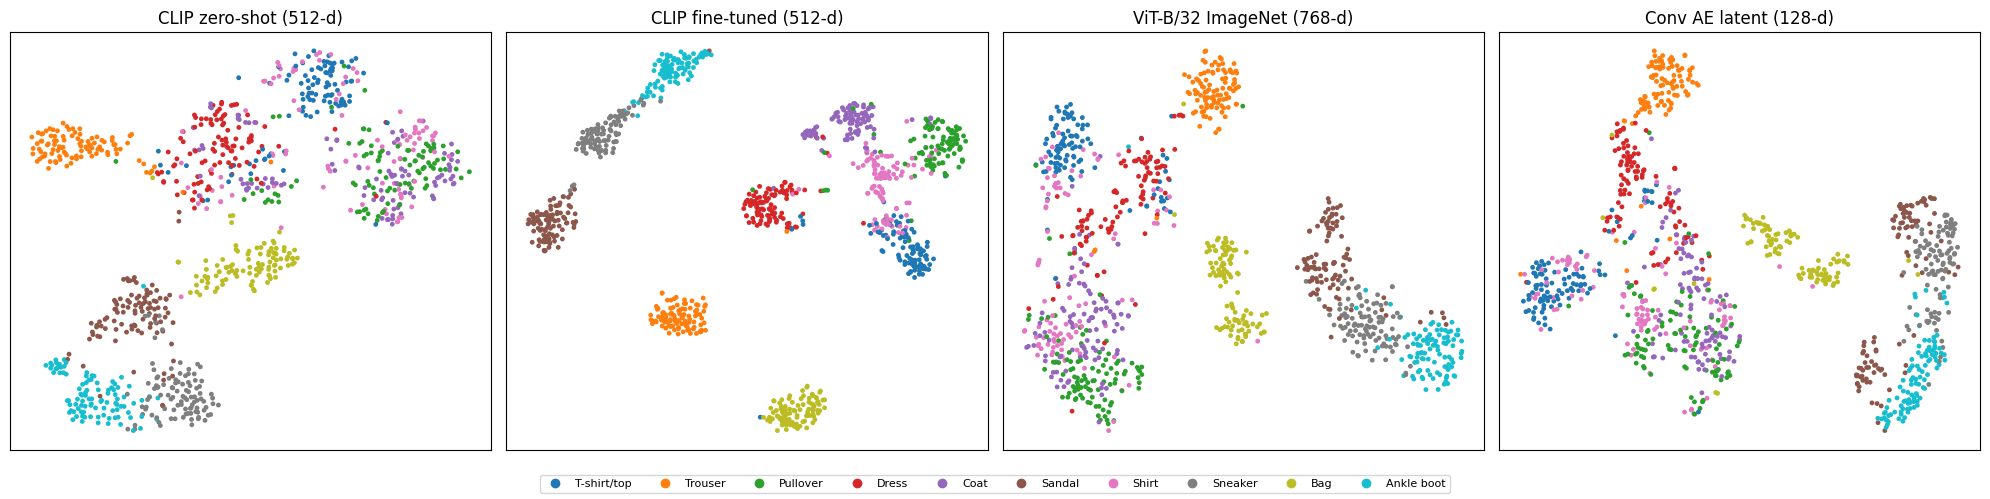

In [25]:
if RUN_EXTENSION:
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for ax, (name, e) in zip(axes, spaces.items()):
        z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(e.numpy())
        sc = ax.scatter(z[:, 0], z[:, 1], c=eval_labels, cmap="tab10", s=6)
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(c / 9), label=class_names[c]) for c in range(10)]
    fig.legend(handles=handles, loc="lower center", ncol=10, fontsize=8)
    plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(os.path.join(OUT_DIR, "tsne_spaces.png"), dpi=150); plt.show()

## 9. Bonus: can we fine-tune and keep the alignment?

Two remedies from the discussion, tested rather than only described.

**9a. WiSE-FT (weight-space ensembling, Wortsman et al., 2022).** No training: interpolate the vision weights, `theta(alpha) = (1 - alpha) * theta_zs + alpha * theta_ft`. `alpha = 0` is zero-shot, `alpha = 1` is Part B. We sweep alpha and track text-to-image mAP, image-to-text top-1 and image-to-image mAP.

**9b. Text-anchored fine-tuning (FLYP-style, Goyal et al., 2023).** Same unfrozen layers and learning rate as Part B, but instead of a new linear head the logits are `logit_scale * cos(image, prompt_c)` against the **frozen** CLIP text embeddings of the 10 prompts. Classification is now done *through* the text space, so the loss itself keeps images close to their prompts. Set `RUN_TEXT_ANCHORED_FT = True` to run (it trains a second model).

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,alpha,T->I P@10,T->I mAP,I->T top-1,I->I mAP,"mean cos(ZS emb, emb)"
0,0.00,0.77,0.607,0.625,0.528,1.000
1,0.25,0.76,0.561,0.677,0.632,0.949
2,0.50,0.43,0.403,0.658,0.777,0.675
3,0.75,0.18,0.234,0.456,0.842,0.396
4,1.00,0.11,0.211,0.320,0.867,0.275


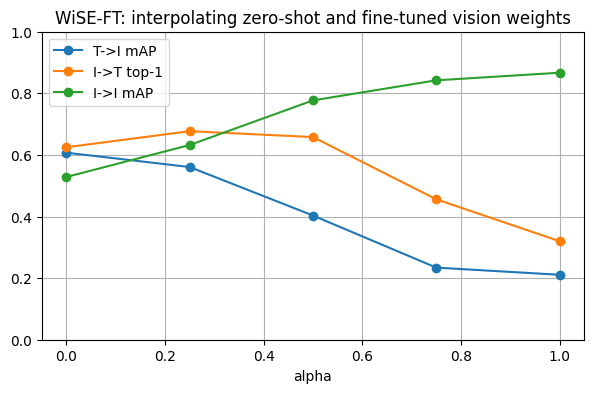

In [26]:
if RUN_WISE_FT:
    zs_vis = {k: v.detach().clone() for k, v in clip_zs.state_dict().items()}
    ft_vis = {k: v.detach().clone() for k, v in clip_ft.state_dict().items()}
    clip_mix = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
    wise_rows = []
    for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
        mixed = {k: ((1 - alpha) * zs_vis[k].float() + alpha * ft_vis[k].float()).to(zs_vis[k].dtype)
                 if zs_vis[k].is_floating_point() else zs_vis[k] for k in zs_vis}
        clip_mix.load_state_dict(mixed)
        e = encode_images(clip_mix, eval_images)
        t2i, _ = text_to_image_metrics(text_emb, e, eval_labels)
        i2t, _ = image_to_text_metrics(e, text_emb, eval_labels)
        i2i = image_to_image_metrics(e, eval_labels)
        wise_rows.append({"alpha": alpha, "T->I P@10": t2i["P@10"], "T->I mAP": t2i["mAP"],
                          "I->T top-1": i2t["top-1"], "I->I mAP": i2i["mAP"],
                          "mean cos(ZS emb, emb)": (img_emb_zs * e).sum(1).mean().item()})
    wise = pd.DataFrame(wise_rows)
    wise.to_csv(os.path.join(OUT_DIR, "results_wise_ft.csv"), index=False)
    display(wise.round(3))
    ax = wise.plot(x="alpha", y=["T->I mAP", "I->T top-1", "I->I mAP"], marker="o", figsize=(7, 4), grid=True)
    ax.set_title("WiSE-FT: interpolating zero-shot and fine-tuned vision weights"); ax.set_ylim(0, 1); plt.show()
    del clip_mix; torch.cuda.empty_cache()

In [27]:
class TextAnchoredClassifier(nn.Module):
    """Logits = scale * cos(image embedding, frozen prompt embedding). No new head."""
    def __init__(self, clip_model, prompt_emb):
        super().__init__()
        self.clip_model = clip_model
        self.register_buffer("prompt_emb", prompt_emb.clone())
        self.scale = clip_model.logit_scale.exp().item()
    def forward(self, pixel_values):
        f = extract_features(self.clip_model.get_image_features(pixel_values=pixel_values))
        return self.scale * F.normalize(f.float(), dim=-1) @ self.prompt_emb.T

if RUN_TEXT_ANCHORED_FT:
    seed_everything()
    clip_anch = build_partB_clip()
    model_anch = TextAnchoredClassifier(clip_anch, text_emb.to(device)).to(device)
    hist_anch = train_with_early_stopping(model_anch, train_loader, val_loader,
                                          epochs=FT_EPOCHS, patience=FT_PATIENCE, lr=FT_LR)
    img_emb_anch = encode_images(clip_anch.eval(), eval_images)
    t2i_a, _ = text_to_image_metrics(text_emb, img_emb_anch, eval_labels)
    i2t_a, _ = image_to_text_metrics(img_emb_anch, text_emb, eval_labels)
    anch = pd.DataFrame({
        "Zero-shot": {"T->I P@10": t2i_zs["P@10"], "T->I mAP": t2i_zs["mAP"], "I->T top-1": i2t_zs["top-1"]},
        "Part B (new head)": {"T->I P@10": t2i_ft["P@10"], "T->I mAP": t2i_ft["mAP"], "I->T top-1": i2t_ft["top-1"]},
        "Text-anchored FT": {"T->I P@10": t2i_a["P@10"], "T->I mAP": t2i_a["mAP"], "I->T top-1": i2t_a["top-1"]},
    }).T
    anch["mean cos(ZS emb, emb)"] = [1.0, drift.mean(), (img_emb_zs * img_emb_anch).sum(1).mean().item()]
    anch.to_csv(os.path.join(OUT_DIR, "results_text_anchored_ft.csv"))
    display(anch.round(3))
else:
    print("Skipped (set RUN_TEXT_ANCHORED_FT = True to run).")

Skipped (set RUN_TEXT_ANCHORED_FT = True to run).


## 10. Results summary

Every number below is computed in this run; nothing is typed by hand.

In [28]:
def fmt(a, b): return f"{a:.3f} -> {b:.3f} ({b - a:+.3f})"

lines = [
    f"Classification accuracy (1000 eval imgs): zero-shot prompts {i2t_zs['top-1']:.3f} | Part B head {head_acc_eval:.3f} "
    f"(full 10k test: {head_acc_full_test:.3f})",
    f"Text->image  P@1  {fmt(t2i_zs['P@1'], t2i_ft['P@1'])}",
    f"Text->image  P@5  {fmt(t2i_zs['P@5'], t2i_ft['P@5'])}",
    f"Text->image  P@10 {fmt(t2i_zs['P@10'], t2i_ft['P@10'])}",
    f"Text->image  mAP  {fmt(t2i_zs['mAP'], t2i_ft['mAP'])}",
    f"Image->text  top-1 {fmt(i2t_zs['top-1'], i2t_ft['top-1'])}",
    f"Image->text  top-3 {fmt(i2t_zs['top-3'], i2t_ft['top-3'])}",
    f"Image->text  top-5 {fmt(i2t_zs['top-5'], i2t_ft['top-5'])}",
    f"Image->image mAP  {fmt(i2i_zs['mAP'], i2i_ft['mAP'])}",
    f"Drift: mean cos(ZS emb, FT emb) same image = {drift.mean():.3f} "
    f"(ZS same-class ref {drift_stats['Ref: ZS cos, same class, different images']:.3f})",
    f"cos(image, own prompt): {fmt(drift_stats['cos(image, own prompt) ZS'], drift_stats['cos(image, own prompt) FT'])}",
    f"Product photos, both-attributes P@5 (mean of {len(valid_queries)} queries): "
    f"{fmt(attr_zs['both P@5'].mean(), attr_ft['both P@5'].mean())}",
]
print("\n".join(lines))

observed_t2i = "degrade" if t2i_ft["mAP"] < t2i_zs["mAP"] - 0.01 else ("improve" if t2i_ft["mAP"] > t2i_zs["mAP"] + 0.01 else "no effect")
print(f"\nPrediction (Section 1): {PREDICTION!r} | observed effect on text->image mAP: {observed_t2i!r} "
      f"-> prediction {'CONFIRMED' if observed_t2i == PREDICTION else 'NOT confirmed'}")
json.dump({"lines": lines, "prediction": PREDICTION, "observed_t2i": observed_t2i},
          open(os.path.join(OUT_DIR, "summary.json"), "w"), indent=2)

Classification accuracy (1000 eval imgs): zero-shot prompts 0.625 | Part B head 0.923 (full 10k test: 0.918)
Text->image  P@1  0.900 -> 0.100 (-0.800)
Text->image  P@5  0.820 -> 0.120 (-0.700)
Text->image  P@10 0.770 -> 0.110 (-0.660)
Text->image  mAP  0.607 -> 0.211 (-0.396)
Image->text  top-1 0.625 -> 0.320 (-0.305)
Image->text  top-3 0.892 -> 0.639 (-0.253)
Image->text  top-5 0.972 -> 0.892 (-0.080)
Image->image mAP  0.528 -> 0.867 (+0.339)
Drift: mean cos(ZS emb, FT emb) same image = 0.275 (ZS same-class ref 0.920)
cos(image, own prompt): 0.269 -> 0.145 (-0.125)
Product photos, both-attributes P@5 (mean of 11 queries): 0.655 -> 0.527 (-0.127)

Prediction (Section 1): 'degrade' | observed effect on text->image mAP: 'degrade' -> prediction CONFIRMED


## 11. Interactive demo (Gradio)

A small app that puts the two models **side by side**, so the effect of fine-tuning can be seen and not only read from a table. It reuses everything computed above (models, cached embeddings, results), nothing is recomputed except the query you type.

| Tab | What it shows |
|---|---|
| Text search | Type any query, see the top results of the zero-shot model next to the fine-tuned one, on product photos or on the FashionMNIST eval set |
| Classify an image | Upload or pick an image: zero-shot probabilities, fine-tuned probabilities (through the text prompts), and the Part B head prediction, plus the drift of this image's embedding |
| Results | The comparison tables and figures from this notebook |
| About | Method in five lines |

Responsive layout (desktop, tablet, phone), light and dark mode. In Colab the app renders inline and `share=True` also prints a public link valid for 72 hours, handy for the presentation.

In [29]:
%pip install -q -U gradio

In [30]:
import gradio as gr
from PIL import Image

print("Gradio", gr.__version__)
GR_MAJOR = int(gr.__version__.split(".")[0])
LOGIT_SCALE = clip_zs.logit_scale.exp().item()
HAS_PRODUCTS = "gal_emb_zs" in globals() and "gallery_images" in globals()
SRC_PRODUCTS, SRC_FMNIST = "Product photos", "FashionMNIST eval set"

# ---------- example images saved to disk for gr.Examples ----------
EX_DIR = os.path.join(OUT_DIR, "demo_examples"); os.makedirs(EX_DIR, exist_ok=True)
example_paths = []
for c in [0, 1, 5, 7, 8, 9]:
    i = int(np.where(eval_labels == c)[0][0])
    p = os.path.join(EX_DIR, f"fmnist_{class_names[c].replace('/', '-').replace(' ', '_')}.png")
    eval_images[i].resize((224, 224), Image.NEAREST).save(p); example_paths.append(p)
if HAS_PRODUCTS:
    for qi in range(min(4, len(valid_queries))):
        gi = int(tops_zs[qi][0]); p = os.path.join(EX_DIR, f"product_{qi}.png")
        gallery_images[gi].save(p); example_paths.append(p)

# ---------- core functions ----------
def _caption(source, i, score):
    if source == SRC_PRODUCTS:
        colour_txt = f"{meta[COLOR_COL].iloc[i]} " if HAS_COLOUR else ""
        return f"{colour_txt}{meta[TYPE_COL].iloc[i]}  |  sim {score:.3f}"
    return f"{class_names[eval_labels[i]]}  |  sim {score:.3f}"

def search(query, source, k):
    query = (query or "").strip()
    if not query:
        return [], [], "Type a query to start."
    k = int(k)
    if source == SRC_PRODUCTS and HAS_PRODUCTS:
        imgs, e_zs, e_ft = gallery_images, gal_emb_zs, gal_emb_ft
    else:
        source, imgs, e_zs, e_ft = SRC_FMNIST, eval_images, img_emb_zs, img_emb_ft
    q = encode_texts(clip_zs, [query])
    outs, tops = [], []
    for e in (e_zs, e_ft):
        s = (q @ e.T)[0]
        v, idx = s.topk(k)
        tops.append(set(idx.tolist()))
        outs.append([(imgs[i], _caption(source, i, float(sc))) for sc, i in zip(v.tolist(), idx.tolist())])
    overlap = len(tops[0] & tops[1])
    note = (f"**{overlap}/{k}** results shared by both models. "
            f"Mean similarity of the top-{k}: zero-shot **{np.mean([float(c.split('sim ')[1]) for _, c in outs[0]]):.3f}**, "
            f"fine-tuned **{np.mean([float(c.split('sim ')[1]) for _, c in outs[1]]):.3f}**.")
    return outs[0], outs[1], note

def classify(image, extra_labels):
    if image is None:
        return None, None, None, "Upload an image or click an example."
    img = image.convert("RGB")
    labels = list(class_names) + [l.strip() for l in (extra_labels or "").split(",") if l.strip()]
    t = encode_texts(clip_zs, [PROMPT_TEMPLATE.format(l) for l in labels])
    ez, ef = encode_images(clip_zs, [img]), encode_images(clip_ft, [img])
    pz = (LOGIT_SCALE * ez @ t.T).softmax(-1)[0].tolist()
    pf = (LOGIT_SCALE * ef @ t.T).softmax(-1)[0].tolist()
    with torch.no_grad():
        pv = processor(images=[img], return_tensors="pt")["pixel_values"].to(device)
        with autocast():
            ph = model_b(pv).float().softmax(-1)[0].cpu().tolist()
    d = float((ez * ef).sum())
    note = (f"Embedding drift for this image: **cos(zero-shot, fine-tuned) = {d:.3f}** "
            f"(eval-set mean {drift.mean():.3f}). The head only knows the 10 FashionMNIST classes; "
            f"the two text-based columns can use any label you add.")
    return (dict(zip(labels, pz)), dict(zip(labels, pf)), dict(zip(class_names, ph)), note)

Gradio 6.32.0


In [31]:
# ---------- look & feel ----------
theme = gr.themes.Soft(
    primary_hue="indigo", secondary_hue="sky", neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"],
    radius_size="lg",
)
CSS = """
.gradio-container {max-width: 1280px !important; margin: 0 auto !important;}
#hero {background: linear-gradient(135deg, #4338ca 0%, #6366f1 45%, #0ea5e9 100%);
       color: #fff; border-radius: 18px; padding: 28px 32px; box-shadow: 0 10px 30px rgba(67,56,202,.25);}
#hero h1 {margin: 0 0 6px 0; font-size: 1.9rem; line-height: 1.2; color: #fff;}
#hero p {margin: 0; opacity: .92; font-size: .98rem; color: #fff;}
.kpi-grid {display: grid; grid-template-columns: repeat(auto-fit, minmax(170px, 1fr)); gap: 12px; margin-top: 20px;}
.kpi {background: rgba(255,255,255,.14); border: 1px solid rgba(255,255,255,.22);
      border-radius: 14px; padding: 12px 14px; backdrop-filter: blur(6px);}
.kpi .l {font-size: .74rem; text-transform: uppercase; letter-spacing: .05em; opacity: .85;}
.kpi .v {font-size: 1.25rem; font-weight: 700; margin-top: 4px; white-space: nowrap;}
.kpi .v .down {color: #fecaca;} .kpi .v .up {color: #bbf7d0;}
.tag {display: inline-block; padding: 3px 12px; border-radius: 999px; font-weight: 600; font-size: .82rem; margin-bottom: 6px;}
.tag-zs {background: #dcfce7; color: #166534;} .tag-ft {background: #ffe4e6; color: #9f1239;} .tag-head {background: #e0e7ff; color: #3730a3;}
.note {font-size: .92rem;}
footer {visibility: hidden;}
@media (max-width: 640px) {
  #hero {padding: 20px 18px; border-radius: 14px;}
  #hero h1 {font-size: 1.35rem;}
  .kpi .v {font-size: 1.05rem;}
}
"""

def _kpi(label, a, b, fmt="{:.3f}"):
    arrow = "up" if b >= a else "down"
    return (f'<div class="kpi"><div class="l">{label}</div>'
            f'<div class="v">{fmt.format(a)} <span class="{arrow}">&rarr; {fmt.format(b)}</span></div></div>')

hero_html = f"""
<div id="hero">
  <h1>Does fine-tuning break CLIP's text-image alignment?</h1>
  <p>Zero-shot CLIP vs CLIP fine-tuned on FashionMNIST (last 2 vision blocks + visual projection, text encoder frozen).
     Values below: zero-shot &rarr; fine-tuned, measured in this notebook.</p>
  <div class="kpi-grid">
    {_kpi("Classification acc.", i2t_zs["top-1"], head_acc_eval)}
    {_kpi("Text &rarr; image mAP", t2i_zs["mAP"], t2i_ft["mAP"])}
    {_kpi("Image &rarr; text top-1", i2t_zs["top-1"], i2t_ft["top-1"])}
    {_kpi("Image &rarr; image mAP", i2i_zs["mAP"], i2i_ft["mAP"])}
    {_kpi("cos(image, own prompt)", drift_stats["cos(image, own prompt) ZS"], drift_stats["cos(image, own prompt) FT"])}
  </div>
</div>
"""

def _fig(name):
    p = os.path.join(OUT_DIR, name)
    return p if os.path.exists(p) else None

blocks_kw = dict(title="CLIP alignment demo", theme=theme, css=CSS)
launch_kw = dict(share=True, debug=False)

sources = [SRC_PRODUCTS, SRC_FMNIST] if HAS_PRODUCTS else [SRC_FMNIST]
example_queries = [q for q, _, _ in (valid_queries if HAS_PRODUCTS else [])] or prompts

with gr.Blocks(**blocks_kw) as demo:
    gr.HTML(hero_html)

    with gr.Tabs():
        # ------------------------------------------------ tab 1
        with gr.Tab("Text search"):
            with gr.Row(equal_height=True):
                with gr.Column(scale=3, min_width=280):
                    q_box = gr.Textbox(label="Query", placeholder='e.g. "a red dress", "a black handbag"',
                                       value=example_queries[0], lines=1)
                with gr.Column(scale=2, min_width=220):
                    src = gr.Radio(sources, value=sources[0], label="Search in")
                with gr.Column(scale=1, min_width=160):
                    k_sl = gr.Slider(4, 12, value=8, step=1, label="Top-k")
            with gr.Row():
                go = gr.Button("Search", variant="primary", scale=0, min_width=140)
            gr.Examples(example_queries[:12], inputs=q_box, label="Attribute queries from Section 7")
            note_s = gr.Markdown(elem_classes="note")
            with gr.Row(equal_height=True):
                with gr.Column(min_width=300):
                    gr.HTML('<span class="tag tag-zs">Zero-shot CLIP</span>')
                    gal_zs = gr.Gallery(show_label=False, columns=4, height="auto", object_fit="contain", preview=False)
                with gr.Column(min_width=300):
                    gr.HTML('<span class="tag tag-ft">Fine-tuned CLIP (Part B)</span>')
                    gal_ft = gr.Gallery(show_label=False, columns=4, height="auto", object_fit="contain", preview=False)
            for trigger in (go.click, q_box.submit):
                trigger(search, [q_box, src, k_sl], [gal_zs, gal_ft, note_s])

        # ------------------------------------------------ tab 2
        with gr.Tab("Classify an image"):
            with gr.Row(equal_height=False):
                with gr.Column(scale=2, min_width=280):
                    img_in = gr.Image(type="pil", label="Image", height=300)
                    extra = gr.Textbox(label="Extra labels (optional, comma-separated)",
                                       placeholder="handbag, watch, sunglasses")
                    cls_btn = gr.Button("Classify", variant="primary")
                    gr.Examples(example_paths, inputs=img_in, label="Examples (FashionMNIST + product photos)")
                with gr.Column(scale=3, min_width=300):
                    note_c = gr.Markdown(elem_classes="note")
                    with gr.Row(equal_height=True):
                        with gr.Column(min_width=200):
                            gr.HTML('<span class="tag tag-zs">Zero-shot (text prompts)</span>')
                            lab_zs = gr.Label(num_top_classes=5, show_label=False)
                        with gr.Column(min_width=200):
                            gr.HTML('<span class="tag tag-ft">Fine-tuned (text prompts)</span>')
                            lab_ft = gr.Label(num_top_classes=5, show_label=False)
                        with gr.Column(min_width=200):
                            gr.HTML('<span class="tag tag-head">Fine-tuned (Part B head)</span>')
                            lab_hd = gr.Label(num_top_classes=5, show_label=False)
            cls_btn.click(classify, [img_in, extra], [lab_zs, lab_ft, lab_hd, note_c])
            img_in.change(classify, [img_in, extra], [lab_zs, lab_ft, lab_hd, note_c])

        # ------------------------------------------------ tab 3
        with gr.Tab("Results"):
            gr.Markdown("### FashionMNIST fixed eval set (1000 images)")
            gr.Dataframe(results.round(3), wrap=True, interactive=False)
            if HAS_PRODUCTS:
                gr.Markdown("### Product photos: attribute queries (top-5)")
                gr.Markdown(f"Dataset: `{PRODUCT_DS}`, relevance from `{TYPE_COL}`"
                            + (f" and `{COLOR_COL}`" if HAS_COLOUR else " only (no colour metadata)"))
                gr.Dataframe(attr.round(2), wrap=True, interactive=False)
            gr.Markdown("### Embedding drift")
            gr.Dataframe(drift_df.round(4).reset_index().rename(columns={"index": "statistic"}),
                         wrap=True, interactive=False)
            with gr.Row():
                for name in ["retrieval_comparison.png", "embedding_drift.png", "tsne_spaces.png"]:
                    if _fig(name):
                        gr.Image(_fig(name), show_label=False, min_width=300)

        # ------------------------------------------------ tab 4
        with gr.Tab("About"):
            gr.Markdown(f"""
- **Models.** `{CLIP_ID}` zero-shot, and the same model after Lab 11 Part B fine-tuning (last {N_UNFROZEN_BLOCKS} vision blocks + `visual_projection`, lr {FT_LR}, cross-entropy head).
- **Key point.** The text encoder is identical in both. Only the image side moved, and no loss kept it aligned with the text.
- **Text search** ranks images by cosine similarity between the query embedding and each image embedding.
- **Classification (text prompts)** is softmax over `{PROMPT_TEMPLATE}` prompts with CLIP's logit scale ({LOGIT_SCALE:.0f}).
- **Eval set** is fixed: {len(eval_images)} FashionMNIST test images, {N_PER_CLASS_EVAL} per class, seed {SEED}.
""")

demo.queue().launch(**launch_kw)

/tmp/ipykernel_405/3327348527.py:60: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(**blocks_kw) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://24355400052e2500a7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Discussion

### Interpretation of the experiment

The experiment separates two capabilities that are often confused. The Part-B classifier is trained to make ten FashionMNIST classes linearly separable, whereas retrieval compares the fine-tuned image embeddings with text embeddings that remain frozen. Therefore, a higher classifier accuracy is not evidence that the image and language modalities are still aligned.

The reported metrics make this distinction explicit: Section 10 prints the change in classification accuracy, text-to-image retrieval, image-to-text retrieval, image-to-image retrieval, prompt similarity, and embedding drift from the same fixed 1,000-image test set. The `summary.json` file records the measured direction of the text-to-image mAP change; no numerical result is manually inserted into this discussion. In particular, a low `cos(ZS, FT)` value indicates that the image representation has moved substantially, while a reduced cosine with the correct prompt and a reduced margin over the best incorrect prompt indicate damage to cross-modal alignment.

This is why monitoring only accuracy is unsafe. Cross-entropy can be reduced after the image clusters move to a geometry that is convenient for a newly trained head but no longer agrees with the original text anchors. Image-to-image retrieval may even improve at the same time: the classes can become more compact internally while their relationship with language becomes worse.

### How alignment can be preserved

| Remedy | Benefit | Trade-off |
|---|---|---|
| Freeze the encoder or train only `visual_projection` | Prevents or limits representation drift | Lower adaptation capacity |
| Use fewer steps, a smaller learning rate, and retrieval-aware early stopping | Keeps the model closer to the pretrained solution | Smaller classification gains |
| Train through frozen class prompts (text-anchored fine-tuning) | Makes the classification loss preserve the image-text geometry | Requires reliable text labels/prompts |
| Use a contrastive image-text objective | Optimises the capability that retrieval actually uses | Requires paired or constructed text |
| WiSE-FT interpolation | Provides a controlled accuracy-alignment compromise without another training run | The interpolation coefficient must be selected on validation data |
| Add feature distillation or an L2-SP penalty | Directly discourages movement from the pretrained image representation | Adds a regularisation hyperparameter |

The WiSE-FT sweep and the optional text-anchored experiment are deliberately implemented in Section 9. Their CSV outputs should be used to select the operating point rather than choosing an alpha from the test set. This keeps the conclusion reproducible and avoids replacing measured evidence with a qualitative claim.

### Product-photo and representation-space interpretation

The product-photo experiment is a meaningful distribution-shift test. Fine-tuning sees centred grayscale 28x28 FashionMNIST images, while the product gallery contains colour, background, scale, and categories such as handbags, watches, wallets, sunglasses, and backpacks. `colour P@5`, `category P@5`, and strict `both P@5` are computed only from metadata that actually exists in the selected dataset. Attributes such as “leather” are not treated as ground truth unless a metadata column supports them.

The optional ViT and autoencoder comparison answers a different question. A pretrained ViT can provide useful image-only features, and an autoencoder can provide compact reconstruction features, but neither has a text encoder. Consequently, neither can answer a query such as “a red dress” without learning an additional cross-modal mapping. Their dimensions (768, 128, and CLIP's 512) also differ, so the comparison is descriptive rather than capacity-matched.

### Limitations and reproducibility

- The evaluation set is fixed at 100 images per class with seed 42, and its indices are saved so every model is tested on identical examples.
- Ten class prompts are sufficient for the required FashionMNIST comparison but are a small sample for P@K; R-precision and mAP are therefore also reported.
- One seed and one fine-tuning recipe do not quantify uncertainty across runs.
- Product-photo relevance is limited to the available metadata, not human judgements.
- Mixed precision is an execution optimisation; the fine-tuning objective and the trainable layers remain those specified by Part B.

The conclusion should be taken from the generated tables and figures, not from a single headline number: the assignment is specifically about whether optimisation for classification changes the independent text-image alignment capability.